# SubjectCamera pose: aruco markers vs SLEAP keypoints + PnP

The TrackCamera films the SubjectCamera, which carries a 2 cm aruco marker (id 199), and the screen, which carries a
5 cm aruco marker. `main-debug-spinnaker.bonsai` estimates the SubjectCamera position on every TrackCamera frame from
these two markers. This notebook reproduces that estimate offline and compares it with a second estimate in which
the SubjectCamera marker is located by the SLEAP model trained on this session
(`261015_v3.single_instance.n=40`) and its pose is solved with PnP.

## Pose chain in the workflow

In the `Tracking` group of `main-debug-spinnaker.bonsai`:

1. `DetectMarkers` (marker size 0.02 m) → `SelectMarker` id 199 → `MarkerViewMatrix` gives the subject marker pose
   in the TrackCamera frame. `TransformRelative` (`Prepend`) then moves the origin from the marker centre to the
   SubjectCamera by `ArucoCalibrationSubject.Offset`, expressed in the marker frame.
2. `DetectMarkers` (marker size 0.05 m) → `SelectMarker` → `MarkerViewMatrix` gives the screen marker pose.
3. `Zip` → `Item1 * Invert(Item2)` expresses the SubjectCamera pose in the screen marker frame.
4. `TransformRelative` (`Append`) shifts the origin by `(-Offset.Y, Offset.X, 0)` of `ArucoCalibrationScreen`, in
   the screen marker frame. The rotations after that only convert the pose into the rendering axes, so positions
   are compared before them.

`MarkerViewMatrix` returns the OpenGL model-view matrix, which is the OpenCV marker pose with the Y and Z camera axes
flipped. The flip cancels in `Item1 * Invert(Item2)`, so the chain can be computed with OpenCV poses directly:

$$T_{\text{screen} \leftarrow \text{subject}} = T(\text{screen offset})\; T_{\text{cam} \leftarrow \text{screen marker}}^{-1}\; T_{\text{cam} \leftarrow \text{subject marker}}\; T(\text{subject offset})$$

Positions are therefore in metres in the screen frame: origin at the screen marker centre plus the screen offset,
x to the right and y up along the screen, z out of the screen towards the room.

Both methods use the same screen marker pose on each frame, so any difference between them comes from the subject
marker pose alone.

In [1]:
import json
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
import pandas as pd
import swc.aeon.io.api as aeon
from IPython.display import Video, display
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle
from swc.aeon.io.video import frames

from ucl_open_freeing_vision_benchmark.rig import UclOpenFreeingVisionBenchmarkRig

from session_io import declare_experiment, find_device_schema, load_camera

## Dataset, rig configuration and camera intrinsics

Marker sizes, offsets and the TrackCamera calibration file are read from the session's rig schema. The calibration
path is relative to `src/`, the working directory of the Bonsai workflow. TrackCamera frames logged before
`StartCameras` are not trigger-driven and are dropped.

The workflow selects screen marker id 2, which is the id of the marker visible on the screen in this session.

In [2]:
root = Path("../temp_data/ses-001_date-2026-10-15T15-25-50")
rig = UclOpenFreeingVisionBenchmarkRig.model_validate_json(next(root.glob("RigSchema/*.json")).read_text())
experiment = declare_experiment(find_device_schema(root))

cameras_started = aeon.load(root, experiment.BehaviorBoard.StartCameras).index.min()
track_video = load_camera(root, experiment.TrackCamera)
track_video = track_video[track_video.index >= cameras_started]
seconds = np.array(aeon.to_seconds(track_video.index))
seconds -= seconds[0]

calibration = cv2.FileStorage(str(Path("../src") / rig.track_camera.calibration_file), cv2.FILE_STORAGE_READ)
camera_matrix = calibration.getNode("camera_matrix").mat()
dist_coeffs = calibration.getNode("distortion_coefficients").mat()

SUBJECT_MARKER_ID = 199
SCREEN_MARKER_ID = 2
subject_marker = rig.aruco_calibration_subject
screen_marker = rig.aruco_calibration_screen

print(f"{len(track_video)} TrackCamera frames over {seconds[-1]:.1f} s")
print(f"subject marker: id {SUBJECT_MARKER_ID}, {subject_marker.aruco_size} m, offset {subject_marker.offset}")
print(f"screen marker: id {SCREEN_MARKER_ID}, {screen_marker.aruco_size} m, offset {screen_marker.offset}")
print(f"calibration: {rig.track_camera.calibration_file}")

4872 TrackCamera frames over 32.5 s
subject marker: id 199, 0.02 m, offset x=0.01 y=0.003 z=0.013
screen marker: id 2, 0.05 m, offset x=0.16 y=-0.08 z=0.0
calibration: ./intrinsics/camera_25170682/2026-10-15/2026-10-15T12-12-48_intrinsics.yml


## Geometry helpers

Marker corners follow the OpenCV aruco convention: top-left, top-right, bottom-right, bottom-left, with x to the
right, y up and z out of the marker. Poses are 4×4 matrices mapping marker coordinates to TrackCamera coordinates.

In [3]:
def marker_corners_3d(size):
    h = size / 2
    return np.array([[-h, h, 0], [h, h, 0], [h, -h, 0], [-h, -h, 0]])


def translation(x, y, z):
    matrix = np.eye(4)
    matrix[:3, 3] = [x, y, z]
    return matrix


def solve_pose(object_points, image_points, flags):
    # Returns (4x4 camera-from-object pose, mean reprojection error in px), or (None, nan) if PnP fails.
    ok, rvec, tvec = cv2.solvePnP(object_points, image_points, camera_matrix, dist_coeffs, flags=flags)
    if not ok:
        return None, np.nan
    pose = np.eye(4)
    pose[:3, :3] = cv2.Rodrigues(rvec)[0]
    pose[:3, 3] = tvec.ravel()
    projected, _ = cv2.projectPoints(object_points, rvec, tvec, camera_matrix, dist_coeffs)
    return pose, np.linalg.norm(projected.reshape(-1, 2) - image_points.reshape(-1, 2), axis=1).mean()


SUBJECT_OFFSET = translation(subject_marker.offset.x, subject_marker.offset.y, subject_marker.offset.z)
SCREEN_OFFSET = translation(-screen_marker.offset.y, screen_marker.offset.x, 0)


def subject_in_screen(camera_from_subject_marker, camera_from_screen_marker):
    # SubjectCamera pose in the screen frame, as computed by the workflow
    return SCREEN_OFFSET @ np.linalg.inv(camera_from_screen_marker) @ camera_from_subject_marker @ SUBJECT_OFFSET

## Method 1: aruco markers

Markers are detected with OpenCV's aruco detector (`DICT_ARUCO_ORIGINAL`) using sub-pixel corner refinement, as in
`latency_analysis.ipynb`. The Bonsai workflow uses the aruco library with `Lines` corner refinement, so corners can
differ slightly from the workflow's. Each marker pose is solved from its four corners with `SOLVEPNP_IPPE_SQUARE`.

In [4]:
aruco_detector_params = cv2.aruco.DetectorParameters()
aruco_detector_params.cornerRefinementMethod = cv2.aruco.CORNER_REFINE_SUBPIX
aruco_detector = cv2.aruco.ArucoDetector(cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_ARUCO_ORIGINAL), aruco_detector_params)

aruco_corners = {marker_id: np.full((len(track_video), 4, 2), np.nan) for marker_id in (SUBJECT_MARKER_ID, SCREEN_MARKER_ID)}
for i, image in enumerate(frames(track_video)):
    corners, ids, _ = aruco_detector.detectMarkers(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY))
    for marker_id, marker_corners in zip([] if ids is None else ids.ravel(), corners):
        if marker_id in aruco_corners:
            aruco_corners[marker_id][i] = marker_corners[0]

for marker_id, corners in aruco_corners.items():
    print(f"marker {marker_id} detected in {np.isfinite(corners[:, 0, 0]).mean():.1%} of frames")

marker 199 detected in 99.4% of frames
marker 2 detected in 100.0% of frames


In [5]:
def marker_poses(corners, size):
    poses, errors = [None] * len(corners), np.full(len(corners), np.nan)
    for i, c in enumerate(corners):
        if np.isfinite(c).all():
            poses[i], errors[i] = solve_pose(marker_corners_3d(size), c, cv2.SOLVEPNP_IPPE_SQUARE)
    return poses, errors


screen_poses, screen_errors = marker_poses(aruco_corners[SCREEN_MARKER_ID], screen_marker.aruco_size)
aruco_poses, aruco_errors = marker_poses(aruco_corners[SUBJECT_MARKER_ID], subject_marker.aruco_size)

## Method 2: SLEAP keypoints + PnP

The SLEAP model exported for Bonsai (`exports/model.onnx`) is run on every TrackCamera frame with onnxruntime. The
exported graph only returns correct coordinates when the image height and width are multiples of the model's maximum
stride (16), so the 540×720 frames are padded with 4 black rows at the bottom; padding at the bottom does not shift
coordinates. Keypoints below the confidence threshold baked into the model (0.2) are returned as NaN.

Inference runs on the CPU at about 150 ms per frame, so the predictions are cached in the session's
`models/predictions` folder. Delete the CSV to recompute it.

In [6]:
model_dir = root / "models/models/261015_v3.single_instance.n=40/exports"
predictions_path = root / "models/predictions/TrackCamera.261015_v3.single_instance.n=40.onnx.csv"
node_names = json.loads((model_dir / "export_metadata.json").read_text())["node_names"]
STRIDE = 16


def predict_keypoints(session, image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    padded = np.pad(gray, ((0, -gray.shape[0] % STRIDE), (0, -gray.shape[1] % STRIDE)))
    peaks, peak_vals = session.run(None, {"image": padded[None, None]})
    return peaks[0], peak_vals[0]


if predictions_path.exists():
    predictions = pd.read_csv(predictions_path, index_col="_frame")
else:
    session = ort.InferenceSession(model_dir / "model.onnx", providers=["CPUExecutionProvider"])
    start = time.perf_counter()
    rows = []
    for image in frames(track_video):
        peaks, peak_vals = predict_keypoints(session, image)
        rows.append(np.column_stack([peaks, peak_vals]).ravel())
    columns = [f"{name}_{field}" for name in node_names for field in ("x", "y", "score")]
    predictions = pd.DataFrame(rows, columns=columns, index=pd.Index(track_video["_frame"].values, name="_frame"))
    predictions.to_csv(predictions_path)
    print(f"inference took {time.perf_counter() - start:.0f} s")

keypoints = np.stack([predictions[[f"{name}_x", f"{name}_y"]].to_numpy() for name in node_names], axis=1)
keypoints = keypoints[np.searchsorted(predictions.index, track_video["_frame"].values)]
print(f"all {len(node_names)} keypoints found in {np.isfinite(keypoints).all(axis=(1, 2)).mean():.1%} of frames")

all 8 keypoints found in 100.0% of frames


### Keypoint positions on the marker

The four corner keypoints are the outer corners of the marker. The other four keypoints are the centres of white
cells of marker 199, on its 7×7 grid of cells counted from the top-left (column, row): `row1_l` (1, 1), `row3_l`
(1, 3), `row4_r` (5, 4) and `row5_l` (2, 5). These positions were found by mapping the labelled keypoints onto the
marker plane through the homography of the labelled corners (all four land within 0.06 cells of a cell centre). The
plot below overlays the 3D model points on the marker image as a check.

Text(0.5, 1.0, 'SLEAP keypoints on marker 199 (m)')

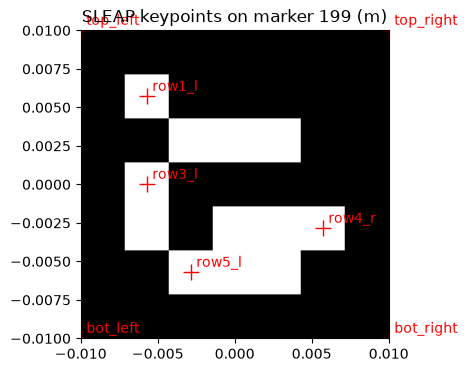

In [7]:
def cell_centre(column, row, size=subject_marker.aruco_size):
    cell = size / 7
    return [(column + 0.5 - 3.5) * cell, -(row + 0.5 - 3.5) * cell, 0]


corners_3d = marker_corners_3d(subject_marker.aruco_size)
model_points = {
    "top_left": corners_3d[0],
    "top_right": corners_3d[1],
    "bot_right": corners_3d[2],
    "bot_left": corners_3d[3],
    "row1_l": cell_centre(1, 1),
    "row3_l": cell_centre(1, 3),
    "row4_r": cell_centre(5, 4),
    "row5_l": cell_centre(2, 5),
}
model_points = np.array([model_points[name] for name in node_names], dtype=float)
corner_nodes = [node_names.index(name) for name in ("top_left", "top_right", "bot_right", "bot_left")]

marker_image = cv2.imread("../markers/aruco-199-100.png", cv2.IMREAD_GRAYSCALE)
h = subject_marker.aruco_size / 2
plt.figure(figsize=(4, 4))
plt.imshow(marker_image, cmap="gray", extent=[-h, h, -h, h])
plt.plot(model_points[:, 0], model_points[:, 1], "r+", markersize=12)
for name, (x, y, _) in zip(node_names, model_points):
    plt.annotate(name, (x, y), color="red", xytext=(4, 4), textcoords="offset points")
plt.title("SLEAP keypoints on marker 199 (m)")

PnP uses all eight keypoints with `SOLVEPNP_IPPE`, the planar-target solver. As a control, the pose is also solved
from the four corner keypoints alone with `SOLVEPNP_IPPE_SQUARE`, the same solver as the aruco method. That variant
separates differences caused by keypoint localisation from differences caused by the extra points.

In [8]:
sleap_poses, sleap_errors = [None] * len(keypoints), np.full(len(keypoints), np.nan)
sleap_corner_poses, sleap_corner_errors = [None] * len(keypoints), np.full(len(keypoints), np.nan)
for i, points in enumerate(keypoints):
    if np.isfinite(points).all():
        sleap_poses[i], sleap_errors[i] = solve_pose(model_points, points, cv2.SOLVEPNP_IPPE)
        sleap_corner_poses[i], sleap_corner_errors[i] = solve_pose(corners_3d, points[corner_nodes], cv2.SOLVEPNP_IPPE_SQUARE)

## Detections in the image

Before comparing poses, the SLEAP corner keypoints are compared with the aruco corners directly in the image. The
example frame shows both, with the reprojection of the SLEAP PnP solution.

In [9]:
corner_distance = np.linalg.norm(keypoints[:, corner_nodes] - aruco_corners[SUBJECT_MARKER_ID], axis=-1)
both_found = np.isfinite(corner_distance).all(axis=1)
print(f"frames with both aruco and SLEAP corners: {both_found.sum()} / {len(track_video)}")
pd.DataFrame(
    corner_distance[both_found], columns=["top_left", "top_right", "bot_right", "bot_left"]
).describe(percentiles=[0.5, 0.95, 0.99]).T.round(2).rename_axis("SLEAP vs aruco corner distance (px)")

frames with both aruco and SLEAP corners: 4845 / 4872


,count,mean,std,min,50%,95%,99%,max
SLEAP vs aruco corner distance (px),,,,,,,,
top_left,4845.0,0.94,0.50,0.0,0.90,1.92,2.20,3.65
top_right,4845.0,1.06,0.54,0.0,1.00,2.01,2.27,3.40
bot_right,4845.0,0.97,0.46,0.0,0.89,1.95,2.24,3.61
bot_left,4845.0,1.05,0.63,0.0,1.00,2.24,3.16,3.87


Text(0.5, 1.0, 'frame 2452')

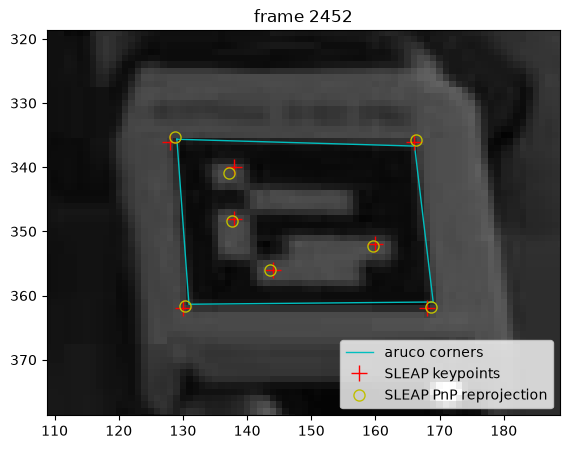

In [10]:
example = np.flatnonzero(both_found)[len(track_video) // 2]
image = next(frames(track_video.iloc[[example]]))
pose = sleap_poses[example]
reprojected, _ = cv2.projectPoints(model_points, cv2.Rodrigues(pose[:3, :3])[0], pose[:3, 3], camera_matrix, dist_coeffs)
reprojected = reprojected.reshape(-1, 2)
c = aruco_corners[SUBJECT_MARKER_ID][example]

fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(image[:, :, ::-1])
ax.plot(*np.vstack([c, c[:1]]).T, "c-", lw=1, label="aruco corners")
ax.plot(*keypoints[example].T, "r+", markersize=12, label="SLEAP keypoints")
ax.plot(*reprojected.T, "yo", mfc="none", markersize=8, label="SLEAP PnP reprojection")
centre = c.mean(axis=0)
ax.set_xlim(centre[0] - 40, centre[0] + 40)
ax.set_ylim(centre[1] + 30, centre[1] - 30)
ax.legend(loc="lower right")
ax.set_title(f"frame {int(track_video['_frame'].iloc[example])}")

## SubjectCamera position in the screen frame

Each subject marker pose is combined with the screen marker pose from the same frame using the workflow's chain.
Positions are shown in millimetres.

aruco: position available in 99.4% of frames
SLEAP PnP: position available in 100.0% of frames
SLEAP PnP (corners only): position available in 100.0% of frames


Text(0.5, 0.98, 'SubjectCamera position in the screen frame')

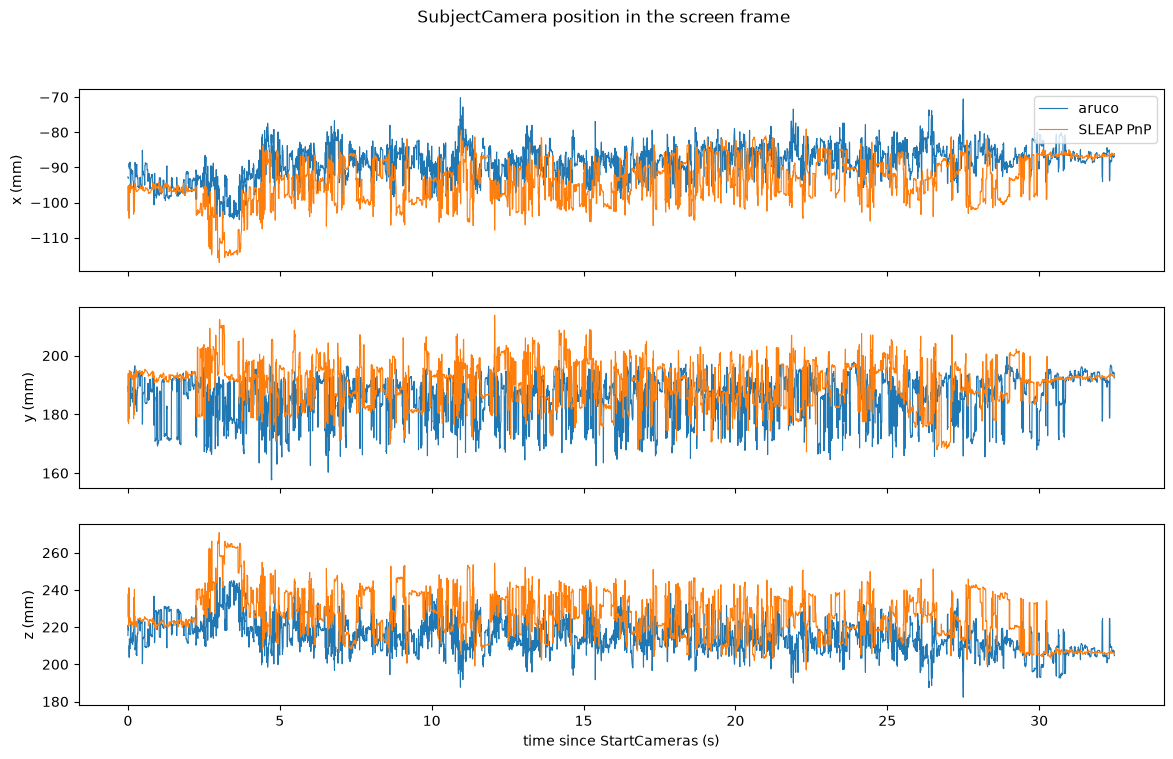

In [11]:
def positions(subject_poses):
    xyz = np.full((len(subject_poses), 3), np.nan)
    rotations = np.full((len(subject_poses), 3, 3), np.nan)
    for i, (subject, screen) in enumerate(zip(subject_poses, screen_poses)):
        if subject is not None and screen is not None:
            pose = subject_in_screen(subject, screen)
            xyz[i], rotations[i] = pose[:3, 3] * 1e3, pose[:3, :3]
    return pd.DataFrame(xyz, columns=["x", "y", "z"]), rotations


methods = {"aruco": aruco_poses, "SLEAP PnP": sleap_poses, "SLEAP PnP (corners only)": sleap_corner_poses}
position, rotation = {}, {}
for name, poses in methods.items():
    position[name], rotation[name] = positions(poses)
    print(f"{name}: position available in {position[name]['x'].notna().mean():.1%} of frames")

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, axis in zip(axes, ["x", "y", "z"]):
    for name in ["aruco", "SLEAP PnP"]:
        ax.plot(seconds, position[name][axis], label=name, lw=0.8)
    ax.set_ylabel(f"{axis} (mm)")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("time since StartCameras (s)")
fig.suptitle("SubjectCamera position in the screen frame")

## Agreement between the methods

The table summarises the difference between each SLEAP estimate and the aruco estimate on frames where both exist:
the bias (mean difference), the standard deviation of the difference, the RMS difference per axis, and the 3D
distance. Neither method is ground truth, so this measures agreement, not accuracy.

In [12]:
def agreement(name, reference="aruco"):
    difference = position[name] - position[reference]
    difference = difference[difference.notna().all(axis=1)]
    distance = np.linalg.norm(difference, axis=1)
    summary = {f"{axis} bias": difference[axis].mean() for axis in "xyz"}
    summary |= {f"{axis} sd": difference[axis].std() for axis in "xyz"}
    summary |= {f"{axis} rms": np.sqrt((difference[axis] ** 2).mean()) for axis in "xyz"}
    summary |= {"3D median": np.median(distance), "3D p95": np.percentile(distance, 95), "3D max": distance.max()}
    return pd.Series(summary, name=f"{name} - {reference} (mm)")


pd.concat([agreement("SLEAP PnP"), agreement("SLEAP PnP (corners only)")], axis=1).round(2)

,SLEAP PnP - aruco (mm),SLEAP PnP (corners only) - aruco (mm)
x bias,-5.26,-5.08
y bias,4.59,0.48
z bias,10.68,10.37
x sd,6.20,6.71
y sd,10.44,11.46
z sd,12.79,13.86
x rms,8.13,8.41
y rms,11.40,11.47
z rms,16.66,17.31
3D median,19.90,21.62


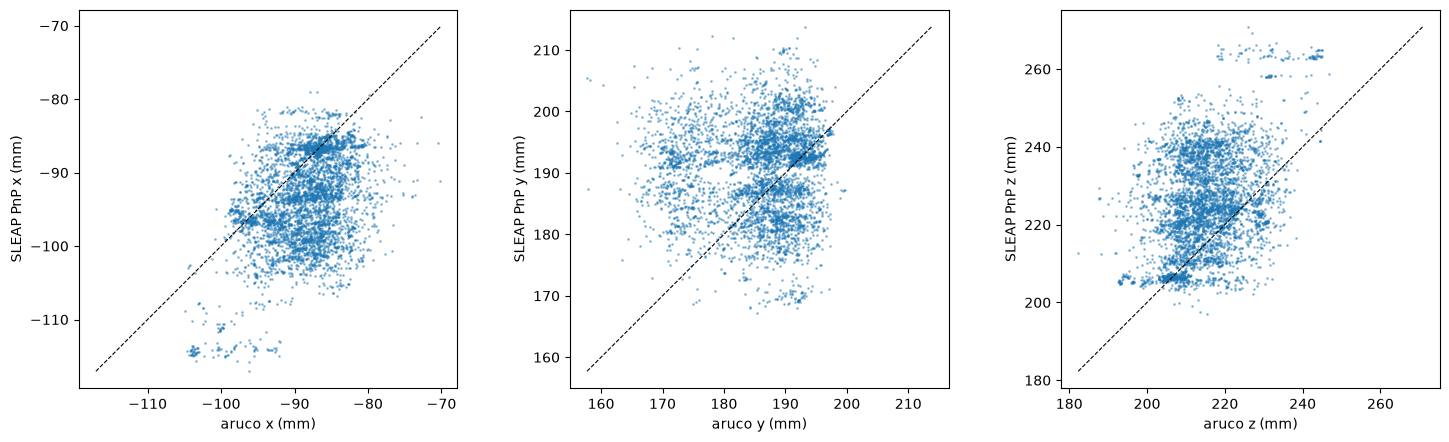

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, axis in zip(axes, ["x", "y", "z"]):
    a, s = position["aruco"][axis], position["SLEAP PnP"][axis]
    ax.plot(a, s, ".", markersize=2, alpha=0.4)
    lims = [np.nanmin([a.min(), s.min()]), np.nanmax([a.max(), s.max()])]
    ax.plot(lims, lims, "k--", lw=0.8)
    ax.set_xlabel(f"aruco {axis} (mm)")
    ax.set_ylabel(f"SLEAP PnP {axis} (mm)")
    ax.set_aspect("equal")
fig.tight_layout()

### Orientation

The angle between the SubjectCamera orientations estimated by the two methods, from the relative rotation
$R_\text{aruco}^\top R_\text{SLEAP}$.

In [14]:
def rotation_angle_deg(a, b):
    relative = np.einsum("nji,njk->nik", a, b)
    return np.degrees(np.arccos(np.clip((np.trace(relative, axis1=1, axis2=2) - 1) / 2, -1, 1)))


angles = pd.DataFrame({name: rotation_angle_deg(rotation["aruco"], rotation[name]) for name in ["SLEAP PnP", "SLEAP PnP (corners only)"]})
angles.describe(percentiles=[0.5, 0.95, 0.99]).T.round(2).rename_axis("orientation difference to aruco (deg)")

,count,mean,std,min,50%,95%,99%,max
orientation difference to aruco (deg),,,,,,,,
SLEAP PnP,4845.0,40.96,50.04,0.23,3.35,112.48,117.26,120.77
SLEAP PnP (corners only),4845.0,53.01,51.69,0.19,5.90,113.25,118.28,120.48


## Noise: frame-to-frame jitter

At 150 Hz the SubjectCamera moves little between consecutive frames, so the frame-to-frame change in the position
estimate is dominated by measurement noise when the camera is still. The median absolute step is a robust measure of
that noise for each method. Lower is better.

In [15]:
pd.DataFrame(
    {name: position[name].diff().abs().median() for name in methods}
).T.round(3).rename_axis("median |frame-to-frame step| (mm)")

,x,y,z
median |frame-to-frame step| (mm),,,
aruco,0.658,0.954,1.251
SLEAP PnP,0.165,0.233,0.283
SLEAP PnP (corners only),0.121,0.185,0.221


Text(0.5, 0.98, '2 s close-up')

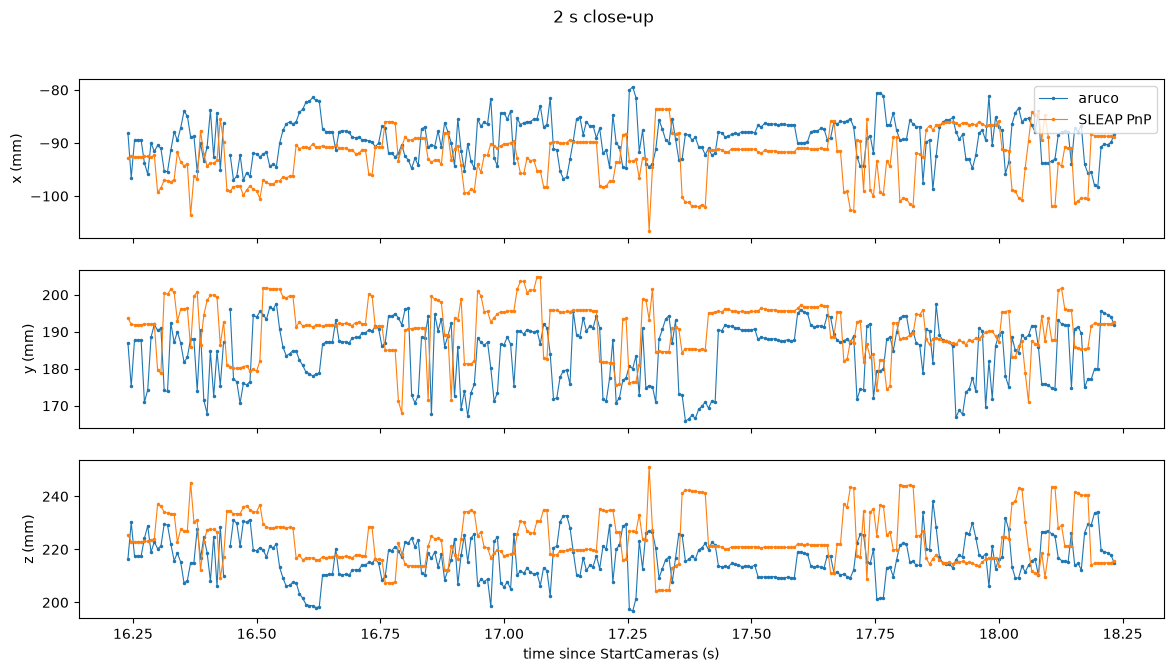

In [16]:
window = slice(*np.searchsorted(seconds, [seconds[-1] / 2, seconds[-1] / 2 + 2]))
fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
for ax, axis in zip(axes, ["x", "y", "z"]):
    for name in ["aruco", "SLEAP PnP"]:
        ax.plot(seconds[window], position[name][axis].iloc[window], ".-", markersize=3, lw=0.8, label=name)
    ax.set_ylabel(f"{axis} (mm)")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("time since StartCameras (s)")
fig.suptitle("2 s close-up")

## Reprojection error

The mean distance between the detected image points and the projection of the fitted marker model, for each pose
estimate. The aruco and corners-only solutions fit four points with six pose parameters; the 8-point SLEAP solution is
more constrained, so its residual also reflects disagreement between the keypoints.

In [17]:
pd.DataFrame(
    {"screen marker (aruco)": screen_errors, "aruco": aruco_errors, "SLEAP PnP": sleap_errors, "SLEAP PnP (corners only)": sleap_corner_errors}
).describe(percentiles=[0.5, 0.95, 0.99]).T.round(3).rename_axis("reprojection error (px)")

,count,mean,std,min,50%,95%,99%,max
reprojection error (px),,,,,,,,
screen marker (aruco),4872.0,0.052,0.027,0.001,0.049,0.101,0.131,0.201
aruco,4845.0,0.211,0.117,0.005,0.192,0.436,0.585,0.789
SLEAP PnP,4872.0,0.610,0.129,0.194,0.597,0.834,0.901,1.021
SLEAP PnP (corners only),4872.0,0.398,0.162,0.172,0.449,0.589,0.779,1.007


## Planar pose ambiguity

The subject marker is about 0.66 m from the TrackCamera, tilted roughly 50° away from it, and only about 37 px wide.
For a small planar target under these conditions, PnP has two solutions that reproject almost equally well. The
second solution mirrors the marker's tilt about the line of sight. Both solvers above (`IPPE_SQUARE` and `IPPE`)
return the solution with the lower reprojection error, so pixel-level noise can make them switch between the two
from frame to frame. Because the SubjectCamera is offset from the marker centre, each switch moves the position
estimate by 10–20 mm. This produces the large orientation differences above, and the step-like jumps in the SLEAP
trajectory.

The ratio between the reprojection errors of the two solutions measures how ambiguous each frame is. Ratios close
to 1 mean the two solutions cannot be told apart.

In [18]:
def pose_candidates(object_points, image_points, flags):
    # All PnP solutions as (4x4 pose, rms reprojection error), best first
    _, rvecs, tvecs, errors = cv2.solvePnPGeneric(object_points, image_points, camera_matrix, dist_coeffs, flags=flags)
    candidates = []
    for rvec, tvec, error in zip(rvecs, tvecs, np.ravel(errors)):
        pose = np.eye(4)
        pose[:3, :3] = cv2.Rodrigues(rvec)[0]
        pose[:3, 3] = tvec.ravel()
        candidates.append((pose, error))
    return candidates


candidates = {
    "aruco": [
        pose_candidates(corners_3d, c, cv2.SOLVEPNP_IPPE_SQUARE) if np.isfinite(c).all() else None
        for c in aruco_corners[SUBJECT_MARKER_ID]
    ],
    "SLEAP PnP": [pose_candidates(model_points, k, cv2.SOLVEPNP_IPPE) for k in keypoints],
    "SLEAP PnP (corners only)": [pose_candidates(corners_3d, k[corner_nodes], cv2.SOLVEPNP_IPPE_SQUARE) for k in keypoints],
}

ambiguity = pd.DataFrame(
    {
        name: [c[1][1] / c[0][1] if c is not None and len(c) > 1 else np.nan for c in method_candidates]
        for name, method_candidates in candidates.items()
    }
)
print("fraction of frames where the second solution's error is within 1.5x of the best:")
print((ambiguity < 1.5).mean().round(2).to_string())

fraction of frames where the second solution's error is within 1.5x of the best:
aruco                       0.23
SLEAP PnP                   1.00
SLEAP PnP (corners only)    0.68


### Resolving the ambiguity

The SubjectCamera's orientation changes little during the session, so the ambiguity can be resolved with a fixed
reference orientation. The reference is the mean orientation of the subject marker on frames where the aruco
solution is unambiguous (second solution error more than 3× the best). On every frame, each method then keeps the
candidate pose closest to that reference. This is not what the Bonsai workflow does; it shows how the methods compare
once the ambiguity is removed. Temporal continuity (the candidate closest to the previous frame) would be the online
equivalent.

In [19]:
def rotation_difference_deg(a, b):
    return np.degrees(np.arccos(np.clip((np.trace(a.T @ b) - 1) / 2, -1, 1)))


unambiguous = [c[0][0][:3, :3] for c in candidates["aruco"] if c is not None and len(c) > 1 and c[1][1] > 3 * c[0][1]]
u, _, vt = np.linalg.svd(np.sum(unambiguous, axis=0))
reference_rotation = u @ vt
print(f"reference orientation from {len(unambiguous)} unambiguous aruco frames")


def closest_to_reference(method_candidates):
    return [
        None if c is None else min(c, key=lambda candidate: rotation_difference_deg(candidate[0][:3, :3], reference_rotation))[0]
        for c in method_candidates
    ]


for name in list(methods):
    position[f"{name}, resolved"], rotation[f"{name}, resolved"] = positions(closest_to_reference(candidates[name]))

resolved_angles = pd.DataFrame(
    {
        name: rotation_angle_deg(rotation["aruco, resolved"], rotation[f"{name}, resolved"])
        for name in ["SLEAP PnP", "SLEAP PnP (corners only)"]
    }
)
display(resolved_angles.describe(percentiles=[0.5, 0.95, 0.99]).T.round(2).rename_axis("orientation difference to aruco, resolved (deg)"))
pd.concat(
    [agreement("SLEAP PnP, resolved", "aruco, resolved"), agreement("SLEAP PnP (corners only), resolved", "aruco, resolved")],
    axis=1,
).round(2)

reference orientation from 1447 unambiguous aruco frames


,count,mean,std,min,50%,95%,99%,max
"orientation difference to aruco, resolved (deg)",,,,,,,,
SLEAP PnP,4845.0,2.44,1.24,0.13,2.25,4.61,6.59,9.84
SLEAP PnP (corners only),4845.0,2.66,1.30,0.16,2.48,4.84,6.79,10.15


,"SLEAP PnP, resolved - aruco, resolved (mm)","SLEAP PnP (corners only), resolved - aruco, resolved (mm)"
x bias,-4.31,-2.96
y bias,6.42,4.41
z bias,8.71,5.90
x sd,4.30,4.79
y sd,6.62,7.37
z sd,8.84,9.86
x rms,6.09,5.62
y rms,9.22,8.58
z rms,12.41,11.49
3D median,12.11,10.52


Text(0.5, 0.98, 'SubjectCamera position in the screen frame, ambiguity resolved')

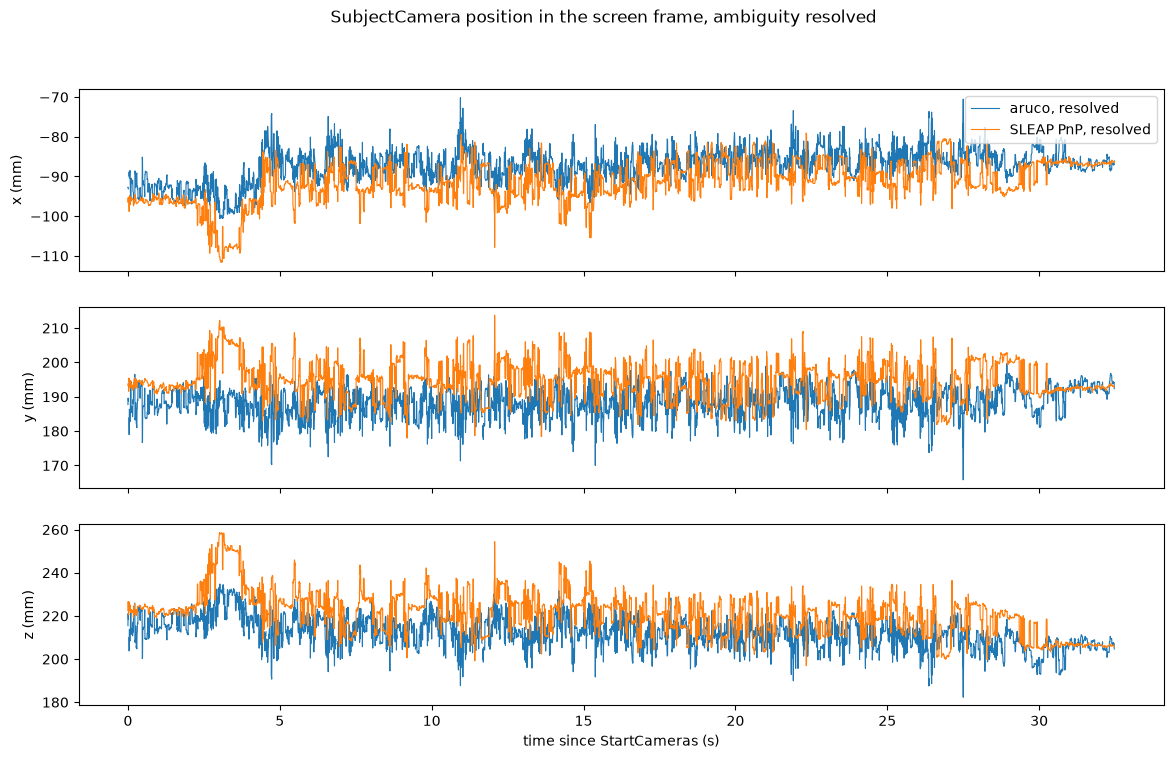

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, axis in zip(axes, ["x", "y", "z"]):
    for name in ["aruco, resolved", "SLEAP PnP, resolved"]:
        ax.plot(seconds, position[name][axis], label=name, lw=0.8)
    ax.set_ylabel(f"{axis} (mm)")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("time since StartCameras (s)")
fig.suptitle("SubjectCamera position in the screen frame, ambiguity resolved")

In [21]:
pd.DataFrame(
    {name: {**position[name].std().add_suffix(" sd"), **position[name].diff().abs().median().add_suffix(" |step|")} for name in position if name.endswith("resolved")}
).T.round(3).rename_axis("resolved trajectories (mm)")

,x sd,y sd,z sd,x |step|,y |step|,z |step|
resolved trajectories (mm),,,,,,
"aruco, resolved",4.053,4.252,6.987,0.598,0.857,1.098
"SLEAP PnP, resolved",5.139,5.292,9.995,0.150,0.217,0.275
"SLEAP PnP (corners only), resolved",5.684,6.241,11.054,0.113,0.169,0.218


## Systematic offset: corner placement

After the ambiguity is resolved, a constant offset between the methods remains. Depth from a single marker depends on
its apparent size: at 0.66 m, a marker that appears 1% larger is placed about 6.6 mm closer to the camera. The SLEAP
corner keypoints are about 1 px from the aruco corners on average. The table splits that difference into the
component along the marker diagonal (positive means the SLEAP corner sits outside the aruco corner) and the side
lengths each method measures.

In [22]:
aruco_subject = aruco_corners[SUBJECT_MARKER_ID][both_found]
sleap_subject = keypoints[both_found][:, corner_nodes]
outward = aruco_subject - aruco_subject.mean(axis=1, keepdims=True)
outward /= np.linalg.norm(outward, axis=-1, keepdims=True)
radial = np.sum((sleap_subject - aruco_subject) * outward, axis=-1)


def side_lengths(corners):
    return np.linalg.norm(np.roll(corners, -1, axis=1) - corners, axis=-1).mean(axis=1)


pd.DataFrame(
    {
        "SLEAP - aruco along diagonal (px)": pd.Series(radial.mean(axis=0), index=["top_left", "top_right", "bot_right", "bot_left"]),
    }
).T.assign(**{"mean side, aruco (px)": side_lengths(aruco_subject).mean(), "mean side, SLEAP (px)": side_lengths(sleap_subject).mean()}).round(3)

,top_left,top_right,bot_right,bot_left,"mean side, aruco (px)","mean side, SLEAP (px)"
SLEAP - aruco along diagonal (px),0.41,0.452,0.11,0.367,29.998,30.523


If the offset comes from apparent size, it should point along the line of sight between the SubjectCamera and the
TrackCamera. The TrackCamera position in the screen frame is the origin of the camera frame mapped through the screen
part of the chain. The table compares the mean offset with its component along the line of sight.

In [23]:
track_camera_in_screen = np.array([(SCREEN_OFFSET @ np.linalg.inv(pose))[:3, 3] for pose in screen_poses if pose is not None]).mean(axis=0) * 1e3
offset = (position["SLEAP PnP, resolved"] - position["aruco, resolved"]).mean().to_numpy()
line_of_sight = track_camera_in_screen - position["aruco, resolved"].mean().to_numpy()
line_of_sight /= np.linalg.norm(line_of_sight)
pd.Series(
    {
        "TrackCamera position in screen frame (mm)": track_camera_in_screen.round(0),
        "mean offset SLEAP - aruco (mm)": offset.round(2),
        "offset length (mm)": np.linalg.norm(offset).round(2),
        "offset along line of sight towards TrackCamera (mm)": (offset @ line_of_sight).round(2),
        "relative size difference SLEAP / aruco - 1": (side_lengths(sleap_subject).mean() / side_lengths(aruco_subject).mean() - 1).round(4),
    }
).to_frame("value")

,value
TrackCamera position in screen frame (mm),"[-346.0, 552.0, 725.0]"
mean offset SLEAP - aruco (mm),"[-4.31, 6.42, 8.71]"
offset length (mm),11.64
offset along line of sight towards TrackCamera (mm),11.64
relative size difference SLEAP / aruco - 1,0.0175


## Video comparison

Short video snippets show, side by side, the TrackCamera frame, the SubjectCamera pose from the aruco method and the
SubjectCamera pose from SLEAP PnP. The frame panel shows the raw frame, with a close-up of the subject marker below it
on which the aruco corners and the SLEAP keypoints are drawn. Each 3D panel shows the SubjectCamera position in the
screen frame (mm) with a trail of the preceding positions, and the subject marker axes (x red, y green, z blue) at
that position. Both 3D panels use the same axis limits, so the motion is directly comparable.

`VIDEO_METHODS` selects the trajectories to show, by their names in `position`. The defaults are the estimates as the
workflow computes them; set them to the `, resolved` trajectories to compare the methods without the planar pose
ambiguity. Every TrackCamera frame is rendered and the videos are written at `OUTPUT_FPS`, so at 150 Hz and 30 fps
they play 5× slower than real time. The videos are H.264 MP4 files saved in the session's `videos` folder. A 2 s
snippet is about 35 MB, so the videos are linked from the notebook rather than embedded in it.

In [ ]:
VIDEO_METHODS = ["aruco", "SLEAP PnP"]
SNIPPETS = [(5, 2), (16, 2), (28, 2)]  # (start, duration) in s since StartCameras
OUTPUT_FPS = 30
TRAIL = 0.5  # s of preceding positions drawn in the 3D panels
AXIS_LENGTH = 10  # mm
ZOOM = (40, 30)  # half width and half height of the marker close-up (px)
video_dir = root / "videos"
video_dir.mkdir(exist_ok=True)

subject_aruco_corners = aruco_corners[SUBJECT_MARKER_ID]
frame_rate = rig.track_camera.trigger_frequency
track_video_shape = next(frames(track_video.iloc[[0]])).shape[:2]


def render_snippet(start, duration, path):
    rows = np.arange(*np.searchsorted(seconds, [start, start + duration]))
    trail = int(TRAIL * frame_rate)
    snippet_xyz = np.concatenate([position[name].iloc[rows].to_numpy() for name in VIDEO_METHODS])
    low, high = np.nanmin(snippet_xyz, axis=0), np.nanmax(snippet_xyz, axis=0)
    centre, half = (low + high) / 2, (high - low).max() / 2 + AXIS_LENGTH

    fig = Figure(figsize=(16, 6.4), dpi=100)
    canvas = FigureCanvasAgg(fig)
    grid = fig.add_gridspec(2, 3, width_ratios=[1, 1.3, 1.3], left=0.01, right=0.96, bottom=0.02, top=0.9, wspace=0.05, hspace=0.08)

    frame_ax, zoom_ax = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[1, 0])
    blank = np.zeros((*track_video_shape, 3), np.uint8)
    frame_image, zoom_image = frame_ax.imshow(blank), zoom_ax.imshow(blank)
    zoom_box = Rectangle((0, 0), 2 * ZOOM[0], 2 * ZOOM[1], fill=False, edgecolor="yellow", lw=0.8)
    frame_ax.add_patch(zoom_box)
    (aruco_outline,) = zoom_ax.plot([], [], "c-", lw=1, label="aruco corners")
    (sleap_points,) = zoom_ax.plot([], [], "r+", markersize=10, label="SLEAP keypoints")
    zoom_ax.legend(loc="lower right", fontsize=8)
    for ax in (frame_ax, zoom_ax):
        ax.set_axis_off()
    frame_ax.set_title("TrackCamera")

    panels = []
    for column, name in enumerate(VIDEO_METHODS, start=1):
        ax = fig.add_subplot(grid[:, column], projection="3d")
        ax.view_init(elev=20, azim=-30, vertical_axis="y")  # looking at the screen from the room
        ax.set_box_aspect((1, 1, 1))
        ax.set(
            **{f"{axis}lim": (c - half, c + half) for axis, c in zip("xyz", centre)},
            **{f"{axis}label": f"{axis} (mm)" for axis in "xyz"},
            title=name,
        )
        (trail_line,) = ax.plot([], [], [], "-", color="0.6", lw=1)
        (point,) = ax.plot([], [], [], "ko", markersize=5)
        axes_lines = [ax.plot([], [], [], "-", color=color, lw=2)[0] for color in ("tab:red", "tab:green", "tab:blue")]
        label = ax.text2D(0.02, 0.98, "", va="top", transform=ax.transAxes, family="monospace")
        panels.append((name, trail_line, point, axes_lines, label))
    title = fig.suptitle("")

    writer = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"avc1"), OUTPUT_FPS, canvas.get_width_height())
    if not writer.isOpened():
        raise RuntimeError(f"could not open an H.264 video writer for {path}")
    for i, image in zip(rows, frames(track_video.iloc[rows])):
        rgb = image[:, :, ::-1]
        frame_image.set_data(rgb)
        zoom_image.set_data(rgb)
        cx, cy = np.nanmean(keypoints[i], axis=0)
        zoom_ax.set_xlim(cx - ZOOM[0], cx + ZOOM[0])
        zoom_ax.set_ylim(cy + ZOOM[1], cy - ZOOM[1])
        zoom_box.set_xy((cx - ZOOM[0], cy - ZOOM[1]))
        aruco_outline.set_data(*np.vstack([subject_aruco_corners[i], subject_aruco_corners[i][:1]]).T)
        sleap_points.set_data(*keypoints[i].T)

        for name, trail_line, point, axes_lines, label in panels:
            xyz = position[name].to_numpy()
            history = xyz[max(rows[0], i - trail) : i + 1]
            trail_line.set_data_3d(*history.T)
            point.set_data_3d(*xyz[i : i + 1].T)
            for axis_line, direction in zip(axes_lines, rotation[name][i].T):
                axis_line.set_data_3d(*np.stack([xyz[i], xyz[i] + AXIS_LENGTH * direction]).T)
            label.set_text("not detected" if np.isnan(xyz[i]).any() else "x {:7.1f}\ny {:7.1f}\nz {:7.1f}".format(*xyz[i]))

        title.set_text(
            f"frame {int(track_video['_frame'].iloc[i])}, t = {seconds[i]:.3f} s "
            f"({frame_rate / OUTPUT_FPS:.0f}× slower than real time)"
        )
        canvas.draw()
        writer.write(cv2.cvtColor(np.asarray(canvas.buffer_rgba())[:, :, :3], cv2.COLOR_RGB2BGR))
    writer.release()


for start, duration in SNIPPETS:
    path = video_dir / f"pose_comparison_{start:05.1f}s-{start + duration:05.1f}s.mp4"
    begin = time.perf_counter()
    render_snippet(start, duration, path)
    print(f"{path.name}: {time.perf_counter() - begin:.0f} s to render, {path.stat().st_size / 1e6:.1f} MB")
    display(Video(path.as_posix(), width=960))

## Summary

- **Detection.** The SLEAP model finds all eight keypoints on every frame, compared with 99.4% for aruco marker 199.
  Its corners lie about 1 px from the aruco corners (95th percentile about 2 px).
- **Pose ambiguity dominates both methods.** At this distance and tilt, the 2 cm marker's pose is ambiguous on most
  frames. Choosing the lowest-error solution, as the workflow does, flips the orientation and moves the position by
  10–20 mm. This affects the aruco estimate and the SLEAP estimate alike, and is the main source of disagreement and
  noise in the raw comparison.
- **With the ambiguity resolved**, the two methods agree on orientation to within a few degrees. Their positions
  differ on average by about 12 mm, pointing along the line of sight to the TrackCamera: SLEAP places the
  SubjectCamera closer to the TrackCamera. This is a depth bias from corner placement. The SLEAP corners, learned
  from the hand labels, sit a fraction of a pixel outside aruco's edge-fitted corners, so the marker appears about
  2% larger. The offset is not constant: it is close to zero in the last seconds of the session and varies with
  the SubjectCamera's position. Neither method is ground truth, so the data cannot say which corner definition is
  right; aruco's corners follow the marker's printed edge.
- **Noise.** The SLEAP trajectories have a smaller median frame-to-frame step than the aruco trajectories, but they
  move in discrete steps and have short excursions of 10–30 mm, mostly in depth. Their overall spread (standard
  deviation) is therefore larger than aruco's. With a marker this small in the image, depth is sensitive to changes
  of a fraction of a pixel in the keypoints.